In [87]:
# Importando bibliotecas 
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np 


In [88]:
# Importando dados do Itau
ticker = yf.Ticker('ITUB4.SA')

In [89]:
# Importando Dados de um ano
# Janela fixa para os resultados serem reproduzíveis
df_historico = ticker.history(start='2025-08-18', end='2026-08-19')

In [90]:
# Mostrando dataset
df_historico

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2025-08-18 00:00:00-03:00,33.395837,33.804403,33.315902,33.537949,21658634,0.000000,0.0
2025-08-19 00:00:00-03:00,33.101567,33.110538,32.186815,32.563477,40817973,0.352816,0.0
2025-08-20 00:00:00-03:00,32.527595,32.760766,32.330294,32.581402,16894884,0.000000,0.0
2025-08-21 00:00:00-03:00,32.330293,32.671082,32.276482,32.617275,16147619,0.000000,0.0
2025-08-22 00:00:00-03:00,32.733863,33.558935,32.635213,33.532028,32623087,0.000000,0.0
...,...,...,...,...,...,...,...
2026-08-12 00:00:00-03:00,39.157455,39.287282,38.338555,38.378502,49492600,0.000000,0.0
2026-08-13 00:00:00-03:00,38.328569,38.857858,38.108863,38.258663,24129000,0.000000,0.0
2026-08-14 00:00:00-03:00,38.208729,39.077566,37.819252,38.947739,39681400,0.000000,0.0


In [91]:
# Estatisticas descritivas do dataset
df_historico.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,251.000000,251.000000,251.000000,251.000000,2.510000e+02,251.000000,251.000000
mean,39.581738,39.966365,39.174221,39.538673,2.542427e+07,0.013746,0.004104
std,4.033012,4.102354,3.906495,4.004260,1.096961e+07,0.142191,0.065013
min,32.330293,32.671082,32.186815,32.563477,7.190900e+06,0.000000,0.000000
25%,35.984345,36.177421,35.791267,36.038231,1.779455e+07,0.000000,0.000000
50%,39.409077,39.863758,39.031430,39.241047,2.243660e+07,0.000000,0.000000
75%,42.580017,42.955207,42.127272,42.499926,3.261201e+07,0.000000,0.000000
max,48.026688,48.633756,47.586079,48.340015,8.033440e+07,2.172789,1.030000


In [92]:
# Resetando Index
df_historico = df_historico.reset_index()

In [93]:
# Valores numéricos
df_historico[['Close', 'High', 'Open', 'Low', 'Volume']] = df_historico[
    ['Close', 'High', 'Open', 'Low', 'Volume']
].apply(pd.to_numeric)


In [94]:
# Ordenando por data
df_historico = df_historico.sort_values('Date').reset_index(drop=True)

In [95]:
# Informações sobre os dados
df_historico.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype                            
---  ------        --------------  -----                            
 0   Date          251 non-null    datetime64[ns, America/Sao_Paulo]
 1   Open          251 non-null    float64                          
 2   High          251 non-null    float64                          
 3   Low           251 non-null    float64                          
 4   Close         251 non-null    float64                          
 5   Volume        251 non-null    int64                            
 6   Dividends     251 non-null    float64                          
 7   Stock Splits  251 non-null    float64                          
dtypes: datetime64[ns, America/Sao_Paulo](1), float64(6), int64(1)
memory usage: 15.8 KB


In [96]:
# Verificando se há valores nulos
df_historico.isnull().sum()

Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

**Média Móveis**: Serve para suavizar o ruído visual(sobe e desce) de um gráfico diário, ajuda a revelar a tendência do ativo em uma janela de tempo, ela é móvel porque avança dia após dia.


In [97]:
# Aplicando Média Móveis 
df_historico['SMA_21'] = df_historico['Close'].rolling(21).mean()
df_historico['SMA_50'] = df_historico['Close'].rolling(50).mean()

**Média Móvel Simples**: Média Aritmética tradicional. boa para identificar níveis de suporte e resistência de longo prazo, é mais estável.


In [98]:
df_historico['SMA_20'] = df_historico['Close'].rolling(20).mean()

**Média Exponencial**: É uma média ponderada, aplica um multiplicador matemático que dá peso maior aos dias mais recentes. O preço de ontem tem muito mais importãncia no calculo do que no preço de 50 dias atrás.

In [99]:
# Aplicando Média Exponencial
df_historico['EMA_21']  = df_historico['Close'].ewm(span=21, adjust=False).mean()
df_historico['EMA_50'] = df_historico['Close'].ewm(span=50, adjust=False).mean()

In [100]:
# Dropando as primeiras linhas (ficam nulos)
df_analise = df_historico.dropna()
df_analise

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,SMA_21,SMA_50,SMA_20,EMA_21,EMA_50
49,2025-10-24 00:00:00-03:00,34.451234,34.576906,34.092182,34.137062,10169911,0.0,0.0,33.972806,33.989790,33.936653,33.971146,33.949231
50,2025-10-27 00:00:00-03:00,34.397373,34.657685,34.280677,34.424301,11194349,0.0,0.0,33.959874,34.007517,33.913205,34.012342,33.967861
51,2025-10-28 00:00:00-03:00,34.325568,34.541000,34.280685,34.541000,10478499,0.0,0.0,33.943100,34.047067,33.887518,34.060402,33.990338
52,2025-10-29 00:00:00-03:00,34.603837,35.465565,34.603837,35.312969,27235466,0.0,0.0,33.955396,34.101698,33.931951,34.174272,34.042205
53,2025-10-30 00:00:00-03:00,35.250126,35.618154,35.025718,35.268078,18657008,0.0,0.0,33.995576,34.154715,33.992990,34.273708,34.090279
...,...,...,...,...,...,...,...,...,...,...,...,...,...
246,2026-08-12 00:00:00-03:00,39.157455,39.287282,38.338555,38.378502,49492600,0.0,0.0,41.890721,41.423538,41.832061,41.428352,41.592968
247,2026-08-13 00:00:00-03:00,38.328569,38.857858,38.108863,38.258663,24129000,0.0,0.0,41.661899,41.422916,41.621245,41.140199,41.462211
248,2026-08-14 00:00:00-03:00,38.208729,39.077566,37.819252,38.947739,39681400,0.0,0.0,41.493936,41.433900,41.474332,40.940884,41.363604
249,2026-08-17 00:00:00-03:00,38.867845,38.927766,38.118850,38.328571,21823400,0.0,0.0,41.324534,41.438632,41.279490,40.703401,41.244583


**Golden Cross**: A média móvel de curto prazo acima da de longo prazo, sinalizando tendência de alta.

**Death Cross**: A média Móvel de curto prazo abaixo da de longo prazo, sinalizando tendência de baixa.

In [101]:
# Identificando Golden Cross e Death Cross

df_historico['Sinal'] = np.where(df_historico['SMA_21'] > df_historico['SMA_50'], 1.0, 0.0)

# Diferença entre linhas 
df_historico['Posicao'] = df_historico['Sinal'].diff()

# Dias exatos ondem ocorrem cruzamentos 
cruzamentos  = df_historico[df_historico['Posicao'] != 0.0].dropna()
print(cruzamentos[['Date', 'Close', 'Posicao']])


                         Date      Close  Posicao
57  2025-11-05 00:00:00-03:00  36.038231      1.0
148 2026-03-23 00:00:00-03:00  42.249958     -1.0
172 2026-04-28 00:00:00-03:00  43.571815      1.0
184 2026-05-15 00:00:00-03:00  39.241047     -1.0
218 2026-07-03 00:00:00-03:00  42.664639      1.0
249 2026-08-17 00:00:00-03:00  38.328571     -1.0


In [102]:
validas = df_historico['SMA_50'].notna()
df_historico.loc[validas, 'Sinal'] = (df_historico['SMA_21'] > df_historico['SMA_50']).astype(float)


In [103]:
fig = go.Figure()

# Linha do Preço de Fechamento Original
fig.add_trace(go.Scatter(x=df_historico['Date'], y=df_historico['Close'],
                         mode='lines', name='Preço de Fechamento', opacity=0.5))

# Linha da SMA 21
fig.add_trace(go.Scatter(x=df_historico['Date'], y=df_historico['SMA_21'],
                         mode='lines', name='SMA 21 Dias', line=dict(color='orange', width=2)))

# Linha da SMA 50
fig.add_trace(go.Scatter(x=df_historico['Date'], y=df_historico['SMA_50'],
                         mode='lines', name='SMA 50 Dias', line=dict(color='red', width=2)))

# Marcadores  Golden Cross
golden_cross = df_historico[df_historico['Posicao'] == 1.0]
fig.add_trace(go.Scatter(x=golden_cross['Date'], y=golden_cross['SMA_50'],
                         mode='markers', name='Golden Cross (Alta)',
                         marker=dict(symbol='triangle-up', color='green', size=12)))

# Marcadores para o Death Cross
death_cross = df_historico[df_historico['Posicao'] == -1.0]
fig.add_trace(go.Scatter(x=death_cross['Date'], y=death_cross['SMA_50'],
                         mode='markers', name='Death Cross (Baixa)',
                         marker=dict(symbol='triangle-down', color='white', size=12)))

# Layout dos Gráficos 
fig.update_layout(title='Análise de Tendências e Cruzamentos de Média Móveis - Itaú',
                  xaxis_title='Período Analisado',
                  yaxis_title='Preço',
                  template='plotly_dark')
fig.update_xaxes(
    dtick='M1',
    tickformat='%m/%Y',
    ticklabelmode='period'
)


fig.show()


Das 3 **Golden Cross**, apenas 11/2025 gerou tendência de alta clara e duradoura, cruzamentos de média curtas (21/50) geram bastante ruídos nesse ativo, média mais longas tendem a ser mais confiáveis.

In [104]:
# Variação Diária do Preço Ativo Itaú

fig = go.Figure(data=[go.Candlestick(x=df_historico['Date'],
                                     open=df_historico['Open'],
                                     high=df_historico['High'],
                                     low=df_historico['Low'],
                                     close=df_historico['Close'])])

fig.update_layout(title='<b>Variação Diária do Preço do Itaú<b>',
                  title_x=0.5,
                  yaxis_title='Preço',
                  xaxis_rangeslider_visible=False)

fig.update_xaxes(
    dtick='M1',
    tickformat='%m/%Y',
    ticklabelmode='period'
)

fig.show()

Do início ao fechamento o retorno bruto foi de +14% no ano.  
O Ativo chegou a **valorizar** 47% da mínima(33.92) até a máxima (47.64), e depois devolvendo boa parte do ganho, fechando o ano abaixo do topo.

**Análise de Volatilidade**: Construindo Bnadas de Bollinger a partir do desvio padrão dos preços, identificando os períodos de maior turbulência.


In [105]:
# Multiplicador padrão do Mercado Financeiro
k = 2

# Calculando Desvio Padrão

df_historico['STD_20'] = df_historico['Close'].rolling(20).std()

#Bandas para janelas de 20 períodos
df_historico['Upper_Band_20'] = df_historico['SMA_20'] + (df_historico['STD_20'] * k)
df_historico['Lower_Band_20'] = df_historico['SMA_20'] - (df_historico['STD_20'] * k)

In [106]:
fig = go.Figure()
fig.add_trace(go.Candlestick(
    x=df_historico['Date'],
    open=df_historico['Open'],
    high=df_historico['High'],
    low=df_historico['Low'],
    close=df_historico['Close'],
    name='Preço'

))

fig.add_trace(go.Scatter(
    x=df_historico['Date'],
    y=df_historico['Upper_Band_20'],
    mode='lines',
    line=dict(color='rgba(150, 150, 150, 0.6)', width=1.5, dash='dot'),
    name='Banda Superior (20)'
))

fig.add_trace(go.Scatter(
    x=df_historico['Date'],
    y=df_historico['Lower_Band_20'],
    mode='lines',
    line=dict(color='rgba(150, 150, 150, 0.6)', width=1.5, dash='dot'),
    name='Banda Inferior (20)'
))

fig.add_trace(go.Scatter(
    x=df_historico['Date'],
    y=df_historico['SMA_20'],
    mode='lines',
    line=dict(color='gray', width=1),
    name='SMA 20'
))

fig.update_layout(
    title='Análise de Volatilidade: Preço vs Bandas de Bollinger (20 Perídos)',
    yaxis_title='Preço do Ativo',
    xaxis_title='Período Analisado',
    xaxis_rangeslider_visible=False, # Removendo o slider inferior duplo
    template='plotly_dark', # O tema escuro ajuda a destacar o preenchimento

    )
fig.update_xaxes(
    dtick='M1',
    tickformat='%m/%Y'
)


fig.show()



A largura das banda mais que dobrou ante o começo e o fim do período- evidência objetiva que a volatilidade do papel aumentou ao longo do ano, e não ficou estável.

Movimentos bruscos visto no gráfico(alta e seguida de forte correção) e com retorno mensais extremos em janeiro.

In [107]:
# Calcular o retorno Diário
df_historico['Retorno_Diario'] = df_historico['Close'].pct_change()

# Calcular Retorno Acumulado
df_historico['Retorno_Acumulado'] = (1 + df_historico['Retorno_Diario']).cumprod()

# Aporte Inicial

aporte_inicial_2 = 4000

In [108]:
# Calculando dois valores 

df_historico['Capital_Acumulado'] = aporte_inicial_2 * df_historico['Retorno_Acumulado']

In [109]:
# Primeira linha possui valor nulo, substituindo com o aporte inicial

df_historico.loc[0, 'Capital_Acumulado'] = aporte_inicial_2

In [110]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=df_historico['Date'],
    y=df_historico['Capital_Acumulado'],
    mode='lines',
    name='Capital Acumulado',
    line=dict(color='#00cc96', width=2), # Verde mercado financeiro
    fill='tozeroy',
    fillcolor='rgba(0, 204, 150, 0.1)'
))

fig.add_trace(go.Scatter(
    x=[df_historico['Date'].iloc[0], df_historico['Date'].iloc[-1]],
    y=[aporte_inicial_2, aporte_inicial_2],
    mode='lines',
    name='Aporte Inicial 4000R$',
    line=dict(color='gray', width=1.5, dash='dash')
))

fig.update_layout(
    title='Evolução do Capital: R$4000 Investidos em Agosto de 2025',
    yaxis_title='Capital Acumulado',
    xaxis_title='Data',
    template='plotly_dark'
)

fig.update_xaxes(
    dtick='M1',
    tickformat='%m/%Y'
)
fig.show()

In [111]:
df_historico['Capital_Acumulado'].max()

np.float64(5765.411113936981)

In [112]:
df_historico['Capital_Acumulado'].iloc[-1]

np.float64(4548.736705182981)

**Capital Inicial**: R$ 4.000  
Quem investisse R$ 4.000 em agosto de 2025 e vendesse no pico (por volta de jan/2026) teria cerca de 44% de ganho.  

**Pico**: R$ 5.765,41 (+44,1%)  

**Valor final**: R$ 4.548,74 (+13,7%)

In [113]:
# Importando API do Banco Central 
from bcb import sgs

# Puxando dados 
cdi_data = sgs.get({'CDI': 12}, start='2025-08-18', end='2026-08-18')

# Mostrando a base de dados exportada
cdi_data


,CDI
Date,
2025-08-18,0.055131
2025-08-19,0.055131
2025-08-20,0.055131
2025-08-21,0.055131
2025-08-22,0.055131
...,...
2026-08-12,0.051660
2026-08-13,0.051660
2026-08-14,0.051660


In [114]:
# Resetando Index
cdi_data = cdi_data.reset_index()

# Ordenando por data
cdi_data = cdi_data.sort_values('Date').reset_index(drop=True)


In [115]:
# Informações 
cdi_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253 entries, 0 to 252
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    253 non-null    datetime64[ns]
 1   CDI     253 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 4.1 KB


In [116]:
# Verificando Valores Nulos
cdi_data.isnull().sum()

Date    0
CDI     0
dtype: int64

In [117]:
# Estatisticas
cdi_data.describe()

,Date,CDI
count,253,253.000000
mean,2026-02-15 11:34:23.241106688,0.054326
min,2025-08-18 00:00:00,0.051660
25%,2025-11-13 00:00:00,0.053400
50%,2026-02-13 00:00:00,0.055131
75%,2026-05-20 00:00:00,0.055131
max,2026-08-18 00:00:00,0.055131
std,NaN,0.001093


In [118]:
# Calculando Retorno Diário  
cdi_data['Retorno_Diario_CDI'] = cdi_data['CDI'] / 100

# Calculando Retorno Acumulado 
cdi_data['Retorno_Acumulado_CDI'] = (1 + cdi_data['Retorno_Diario_CDI']).cumprod()
cdi_data['Retorno_Acumulado_CDI.Pct'] = (cdi_data['Retorno_Acumulado_CDI'] - 1) * 100

# Calculando Capital Acumulado com aporte de 4000
aporte_inicial_cdi = 4000
cdi_data['Capital_Acumulado_CDI'] = aporte_inicial_cdi * cdi_data['Retorno_Acumulado_CDI']



In [119]:
cdi_data

,Date,CDI,Retorno_Diario_CDI,Retorno_Acumulado_CDI,Retorno_Acumulado_CDI.Pct,Capital_Acumulado_CDI
0,2025-08-18,0.055131,0.000551,1.000551,0.055131,4002.205240
1,2025-08-19,0.055131,0.000551,1.001103,0.110292,4004.411696
2,2025-08-20,0.055131,0.000551,1.001655,0.165484,4006.619368
3,2025-08-21,0.055131,0.000551,1.002207,0.220706,4008.828257
4,2025-08-22,0.055131,0.000551,1.002760,0.275959,4011.038364
...,...,...,...,...,...,...
248,2026-08-12,0.051660,0.000517,1.144929,14.492875,4579.714998
249,2026-08-13,0.051660,0.000517,1.145520,14.552022,4582.080878
250,2026-08-14,0.051660,0.000517,1.146112,14.611200,4584.447981
251,2026-08-17,0.051660,0.000517,1.146704,14.670408,4586.816307


In [120]:
# Mudando o Fuso-Horário da Coluna 'Date' para fazer o merge 
cdi_data['Date'] = cdi_data['Date'].dt.tz_localize('America/Sao_Paulo')

In [121]:
df_comparativo = pd.merge(df_historico, cdi_data, on='Date', how='left')

In [122]:
# Visualizando o merge
df_comparativo

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,SMA_21,SMA_50,...,Upper_Band_20,Lower_Band_20,Retorno_Diario,Retorno_Acumulado,Capital_Acumulado,CDI,Retorno_Diario_CDI,Retorno_Acumulado_CDI,Retorno_Acumulado_CDI.Pct,Capital_Acumulado_CDI
0,2025-08-18 00:00:00-03:00,33.395837,33.804403,33.315902,33.537949,21658634,0.000000,0.0,NaN,NaN,...,NaN,NaN,NaN,NaN,4000.000000,0.055131,0.000551,1.000551,0.055131,4002.205240
1,2025-08-19 00:00:00-03:00,33.101567,33.110538,32.186815,32.563477,40817973,0.352816,0.0,NaN,NaN,...,NaN,NaN,-0.029056,0.970944,3883.776786,0.055131,0.000551,1.001103,0.110292,4004.411696
2,2025-08-20 00:00:00-03:00,32.527595,32.760766,32.330294,32.581402,16894884,0.000000,0.0,NaN,NaN,...,NaN,NaN,0.000550,0.971479,3885.914694,0.055131,0.000551,1.001655,0.165484,4006.619368
3,2025-08-21 00:00:00-03:00,32.330293,32.671082,32.276482,32.617275,16147619,0.000000,0.0,NaN,NaN,...,NaN,NaN,0.001101,0.972548,3890.193240,0.055131,0.000551,1.002207,0.220706,4008.828257
4,2025-08-22 00:00:00-03:00,32.733863,33.558935,32.635213,33.532028,32623087,0.000000,0.0,NaN,NaN,...,NaN,NaN,0.028045,0.999823,3999.293885,0.055131,0.000551,1.002760,0.275959,4011.038364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246,2026-08-12 00:00:00-03:00,39.157455,39.287282,38.338555,38.378502,49492600,0.000000,0.0,41.890721,41.423538,...,44.395309,39.268812,-0.014615,1.144331,4577.322524,0.051660,0.000517,1.144929,14.492875,4579.714998
247,2026-08-13 00:00:00-03:00,38.328569,38.857858,38.108863,38.258663,24129000,0.000000,0.0,41.661899,41.422916,...,44.618635,38.623856,-0.003123,1.140757,4563.029615,0.051660,0.000517,1.145520,14.552022,4582.080878
248,2026-08-14 00:00:00-03:00,38.208729,39.077566,37.819252,38.947739,39681400,0.000000,0.0,41.493936,41.433900,...,44.696672,38.251992,0.018011,1.161304,4645.214184,0.051660,0.000517,1.146112,14.611200,4584.447981
249,2026-08-17 00:00:00-03:00,38.867845,38.927766,38.118850,38.328571,21823400,0.000000,0.0,41.324534,41.438632,...,44.770650,37.788330,-0.015897,1.142842,4571.367410,0.051660,0.000517,1.146704,14.670408,4586.816307


In [123]:

# Removendo Valores Nulos
df_comparativo = pd.merge(df_historico[['Date','Close']], cdi_data[['Date','Capital_Acumulado_CDI']], on='Date', how='left').ffill().dropna()


In [124]:
# Verificando Valores Nulos
df_comparativo.isnull().sum()

Date                     0
Close                    0
Capital_Acumulado_CDI    0
dtype: int64

In [125]:
# Aplicando Normalização de Base 100 para comparação igualitária
df_comparativo['Itau_Norm'] = (df_comparativo['Close'] / df_comparativo['Close'].iloc[0]) * 100
df_comparativo['CDI_Norm'] = (df_comparativo['Capital_Acumulado_CDI'] / df_comparativo['Capital_Acumulado_CDI'].iloc[0]) * 100

In [126]:

# Gráfico

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=df_comparativo['Date'],
    y=df_comparativo['Itau_Norm'],
    mode='lines',
    name='Itaú',
    line=dict(color='#FFA500', width=2)

))

fig.add_trace(go.Scatter(
    x=df_comparativo['Date'],
    y=df_comparativo['CDI_Norm'],
    mode='lines',
    name='CDI',
    line=dict(color='#00FF00', width=2)
))

fig.update_layout(
    title='Comparativo de Desempenho (Base 100): Itaú VS CDI ',
    yaxis_title='Crescimento Acumulado (Base 100)',
    xaxis_title='Período Analisado',
    template='plotly_dark',
    width=900, height=500 
)

fig.update_yaxes(type='linear')
fig.update_xaxes(dtick='M1' , tickformat='%m/%Y')
fig.show()


In [127]:
print(df_comparativo[['Itau_Norm', 'CDI_Norm']].iloc[-1])
print(df_comparativo['Itau_Norm'].max())

Itau_Norm    113.718418
CDI_Norm     114.666430
Name: 250, dtype: float64
144.13527784842464


Ambos partem do 113,09 **Itáu** termina em 111,09 e o **CDI** termina em 111,55. **Itaú** chegou a 141.60.  
**Conculusão Final**: Itáu rendeu menos que o **CDI**.

**CDI**: Renda Fixa  

**ITÁU**: Renda Variável

**Análise Fundamentalista**

**ROE**: Rentabilidade do Banco.
**P/L (Preço sobre Lucro) e P/VP (Preço sobre Valor Patrimonial)**: indicam se a ação está barata ou cara em relação ao lucro gerado e ao seu patrimônio líquido.  

**Dividend Yield e JCP**: avaliam o retorno em dinheiro pago aos acionistas por meio de dividendos e Juros sobre Capital Próprio.  

**Índice de Inadimplência (NPL) e Cobertura**: mostram a qualidade da carteira de crédito e o risco de calote dos clientes.

In [128]:
# Obtendo Lucro Líquido Via API
DRE = ticker.income_stmt
lucro_liquido = DRE.loc['Net Income'].iloc[0]

# Patrimônio Líquido mais recente
balanco = ticker.balance_sheet
patrimonio_liquido = balanco.loc['Stockholders Equity'].iloc[0]


In [129]:
# Calcular Roe 
roe = (lucro_liquido / patrimonio_liquido) * 100

In [130]:
print(f'lucro_liquido: {lucro_liquido:,.2f}')
print(f'Patrimônio Líquido: {patrimonio_liquido:,.2f}')
print(f'ROE: {roe:.2f}')

lucro_liquido: 44,857,000,000.00
Patrimônio Líquido: 204,501,000,000.00
ROE: 21.93


In [131]:
data_bruta = DRE.columns[0]
data_formatada = pd.to_datetime(data_bruta).strftime('%d/%m/%Y')

In [132]:
# Tranformando para Bilhões
lucro_bi = lucro_liquido / 1e9
patrimonio_bi = patrimonio_liquido / 1e9

In [133]:
# Três Metricas
barras = pd.DataFrame({
    'Métrica': ['Lucro Líquido (bi)', 'Patrimônio Líquido (bi)', 'ROE (%)'],
    'Valor': [lucro_bi, patrimonio_bi, roe]
})

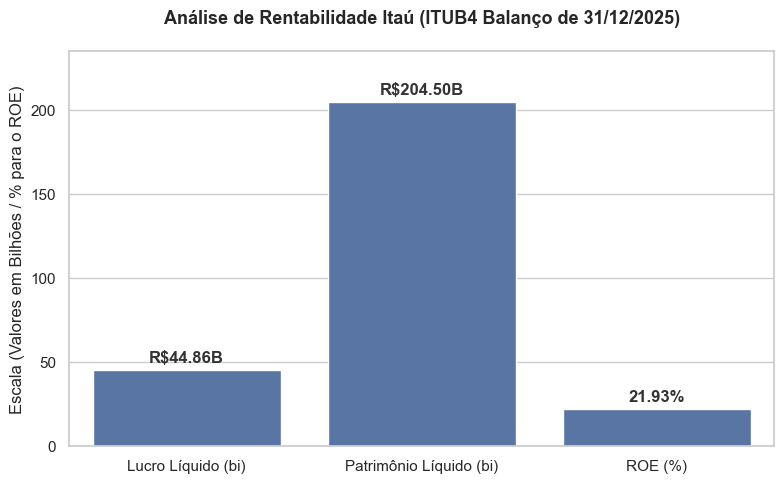

In [134]:
plt.figure(figsize=(8, 5))
sns.set_theme(style='whitegrid')
grafico = sns.barplot(data=barras , x='Métrica', y='Valor')

# Adicionando valores nas barras
for p in grafico.patches:
    valor_barra = p.get_height()
    sufixo = "%" if valor_barra == roe else "B"
    prefixo  = "" if valor_barra == roe else "R$"

    grafico.annotate(f'{prefixo}{valor_barra:.2f}{sufixo}',
                     (p.get_x() + p.get_width() / 2., valor_barra),
                     ha='center', va='center',
                     xytext=(0,9),
                     textcoords='offset points',
                     fontweight='bold', color='#333333')
plt.title(f'Análise de Rentabilidade Itaú (ITUB4 Balanço de {data_formatada})', fontsize=13, fontweight='bold', pad=20)
plt.ylabel('Escala (Valores em Bilhões / % para o ROE)')
plt.xlabel('')
plt.ylim(0, max(lucro_bi, patrimonio_bi, roe) * 1.15)
plt.tight_layout()
plt.show()


Um **ROE** de 21.93% é forte e bate com a realidade do setor bancário.

**Lucro Líquido** Maior lucro registrado do banco e o maior resultado registrado por uma banco brasileiro.

In [135]:
# Preco e Total de Ações
preco_atual = ticker.info.get('currentPrice')
total_acoes = ticker.info.get('sharesOutstanding')
valor_mercado = ticker.info.get('marketCap')

In [136]:
if total_acoes is None:
    df_acoes = ticker.get_shares_full()
    if df_acoes is not None and not df_acoes.empty:
        total_acoes = df_acoes.iloc[-1]

In [137]:
if valor_mercado is None and total_acoes and preco_atual:
    valor_mercado = preco_atual * total_acoes
  


In [138]:
pl = valor_mercado / lucro_liquido
pvp = valor_mercado / patrimonio_liquido
print(f'Valor de mercado: R$ {valor_mercado/1e9:,.2f} bi')
print(f'P/L: {pl:.2f} | P/VP: {pvp:.2f}')
print(f'Conferência (P/L x ROE): {pl * roe / 100:.2f}')


Valor de mercado: R$ 446.72 bi
P/L: 9.96 | P/VP: 2.18
Conferência (P/L x ROE): 2.18


In [139]:
# Duas Metricas
barras_2 = pd.DataFrame({
    'Métrica': ['Preço/Lucro', 'Preço/Valor Patrimônial'],
    'Valor': [pl, pvp]
})

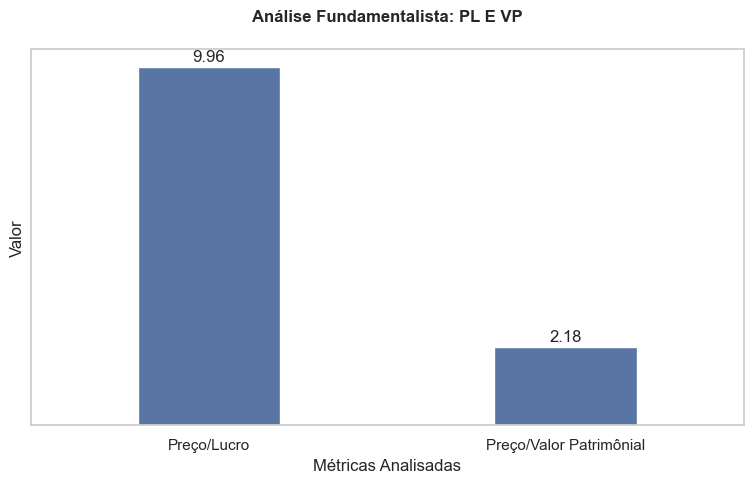

In [140]:
plt.figure(figsize=(8, 5))
sns.set_theme(style='whitegrid')
grafico = sns.barplot(data=barras_2 , x='Métrica', y='Valor', width=0.4)
grafico.bar_label(grafico.containers[0], fmt='%.2f', padding=2)
plt.title('Análise Fundamentalista: PL E VP', fontweight='bold', pad=20)
plt.xlabel('Métricas Analisadas')
plt.tight_layout()
plt.yticks([])
plt.show()

**P/L**: O mercado paga o equivalente a 9,3 anos de lucro pela ação, nem "caro" e nem "barato".  
**P/VP**: Banco com **ROE de 21.93%** tendem a negociar com ágio sobre o valor patromonial.

**Conclusão Final**: Não indicam nem  subvalorização e nem sobrevalorização, estão alinhados com a rentabilidade apresentada.

In [141]:
# Historico de Preços e Dividendos  em 5 anos
historico_precos = ticker.history(period='5y', auto_adjust=False)
historico_dividendos = ticker.dividends

$ITUB4.SA: possibly delisted; no price data found  (1d 1927-12-02 -> 2026-11-07)


In [142]:
# Indíces sem fuso horário 
historico_precos.index = pd.to_datetime(historico_precos.index).tz_localize(None)
historico_dividendos.index = pd.to_datetime(historico_dividendos.index).tz_localize(None)


In [143]:
# Agrupamos e somamos o dividendos por ano
div_anuais = historico_dividendos.groupby(historico_dividendos.index.year).sum()
div_anuais = div_anuais.loc[2021:2025]

In [144]:
# Preco de fechamendo no ultimo dia de cada ano
precos_anuais = historico_precos['Close'].groupby(historico_precos.index.year).last()
precos_anuais = precos_anuais.loc[2021:2025]


In [145]:
# Dividend Yield Historico por ano (%)
dy_historico = (div_anuais / precos_anuais) * 100

In [146]:
# Tranformando Series em DataFrame e resetando o índice
dy_df = dy_historico.to_frame().reset_index()
# Remomeando as colunas 
dy_df.columns = ['Ano', 'Dividend_Yield']



In [147]:

# Gráfico
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=dy_df['Ano'],
    y=dy_df['Dividend_Yield'],
    mode='lines+markers+text',
    text=dy_df['Dividend_Yield'].round(2),
    textposition='top center',
    name='Itaú',
    line=dict(color='#26A69A', width=2)
    

))

fig.update_layout(
    title='Evolução do Dividend Yield do Itaú ao longo dos Anos',
    yaxis_title='DY',
    xaxis_title='Período Analisado',
    template='plotly_dark',
    width=1000, height=500
)

fig.update_xaxes(tickformat='%Y')
fig.show()


Entre 2021 e 2023 houve uma queda significativa, e a partir de 2024 há um salto expressivo e em 2025 também, dobrando em dois anos.

In [148]:
# Criando uma função para extrair dados Inadimplência
def extrair_serie_bacen(codigo_serie, nome_coluna):
    url = f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo_serie}/dados?formato=json"
    df = pd.read_json(url)
    df["data"] = pd.to_datetime(df["data"], dayfirst=True)
    df[nome_coluna] = pd.to_numeric(df["valor"])
    return df[["data", nome_coluna]].set_index("data")


# 2. CHAMADA DA FUNÇÃO (encostado na margem esquerda, sem recuo)
df_inadimplencia = extrair_serie_bacen(21083, "Inadimplencia_PF")
df_inadimplencia.head()

,Inadimplencia_PF
data,
2011-03-01,1.96
2011-04-01,2.04
2011-05-01,2.15
2011-06-01,2.09
2011-07-01,2.18


In [149]:
# Puxando os Dados 
series_alvo = {
    21083: "Inadimplencia_PF",
    21084: "Inadimplencia_PJ", 
    20717: "Taxa_Juros_PF",  
    19882: "Comprometimento_Renda",  
}

In [150]:
# Puxando todos os dados de uma vez
lista_data = []
for codigo, nome_coluna in series_alvo.items():
    df = extrair_serie_bacen(codigo, nome_coluna)
    lista_data.append(df)
df_itau_inadimplencia = pd.concat(lista_data, axis=1)

In [151]:
# Removendo valores Nulos 
df_itau_inadimplencia.dropna(inplace=True)
# Visualizando Dados
df_itau_inadimplencia
# Resetando Index para coluna
df_itau_inadimplencia.reset_index('data', inplace=True)

In [152]:
df_itau_inadimplencia = df_itau_inadimplencia.rename(columns={'data': 'Date'})


In [153]:
df_historico_2 = yf.download("ITUB4.SA", start="2011-01-01", end="2021-12-31")

# Pegando apenas o preço de fechamento e transformando em mensal
df_itau_historico = df_historico_2[['Close']].resample('ME').last()
# Resetando Index
df_historico_2.reset_index()

[*********************100%***********************]  1 of 1 completed


Price,Date,Close,High,Low,Open,Volume
Ticker,,ITUB4.SA,ITUB4.SA,ITUB4.SA,ITUB4.SA,ITUB4.SA
0,2011-01-03,7.153135,7.225243,7.111673,7.138713,11346613
1,2011-01-04,7.210827,7.252290,7.138719,7.156746,14372311
2,2011-01-05,7.318985,7.327999,7.127899,7.174769,13758960
3,2011-01-06,7.145924,7.299153,7.138713,7.284732,19336594
4,2011-01-07,6.971063,7.185584,6.933206,7.131503,17289272
...,...,...,...,...,...,...
2723,2021-12-23,13.877644,14.027215,13.767091,13.871140,25353141
2724,2021-12-27,14.020717,14.111760,13.858140,13.968692,15891231
2725,2021-12-28,13.968699,14.111767,13.916675,14.066246,17328328


In [154]:

# Fechamento Mensal 
fechamento_mensal = df_historico_2[['Close']].resample('ME').last()
# Preço Mensal
retorno_mensal = fechamento_mensal.pct_change()
retorno_mensal



Price,Close
Ticker,ITUB4.SA
Date,
2011-01-31,NaN
2011-02-28,0.039968
2011-03-31,0.062593
2011-04-30,-0.045979
2011-05-31,-0.033649
...,...
2021-08-31,0.025086
2021-09-30,-0.064511


In [155]:
df_retorno_mensal = retorno_mensal.reset_index()

In [156]:
df_retorno_mensal['Date'] = df_retorno_mensal['Date'].dt.tz_localize(None)

In [157]:
df_retorno_mensal

Price,Date,Close
Ticker,,ITUB4.SA
0,2011-01-31,NaN
1,2011-02-28,0.039968
2,2011-03-31,0.062593
3,2011-04-30,-0.045979
4,2011-05-31,-0.033649
...,...,...
127,2021-08-31,0.025086
128,2021-09-30,-0.064511
129,2021-10-31,-0.193844


In [158]:
df_retorno_mensal

Price,Date,Close
Ticker,,ITUB4.SA
0,2011-01-31,NaN
1,2011-02-28,0.039968
2,2011-03-31,0.062593
3,2011-04-30,-0.045979
4,2011-05-31,-0.033649
...,...,...
127,2021-08-31,0.025086
128,2021-09-30,-0.064511
129,2021-10-31,-0.193844


In [159]:
# Comprimindo a coluna
df_retorno_mensal.columns = df_retorno_mensal.columns.get_level_values(0)

# Tranformando em Datetime
df_itau_inadimplencia['Date'] = pd.to_datetime(df_itau_inadimplencia['Date'])
df_retorno_mensal['Date'] = pd.to_datetime(df_retorno_mensal['Date'])

df_itau_inadimplencia['Mes_Ano'] = df_itau_inadimplencia['Date'].dt.to_period('M')
df_retorno_mensal['Mes_Ano'] = df_retorno_mensal['Date'].dt.to_period('M')

df_merge_itau = pd.merge(df_itau_inadimplencia, df_retorno_mensal, on='Mes_Ano', how='left')
df_merge_itau = df_merge_itau.drop(columns=['Date_x', 'Date_y'], errors='ignore')

display(df_merge_itau)

,Inadimplencia_PF,Inadimplencia_PJ,Taxa_Juros_PF,Comprometimento_Renda,Mes_Ano,Close
0,1.96,4.62,37.92,41.90,2011-03,0.062593
1,2.04,4.67,38.71,41.99,2011-04,-0.045979
2,2.15,4.82,38.40,42.28,2011-05,-0.033649
3,2.09,4.79,38.28,42.59,2011-06,0.017360
4,2.18,4.90,38.67,42.74,2011-07,-0.135517
...,...,...,...,...,...,...
121,1.33,2.95,28.66,58.27,2021-04,-0.013145
122,1.57,3.01,27.99,59.26,2021-05,0.075382
123,1.54,2.91,27.93,59.55,2021-06,0.009314
124,1.58,2.94,28.37,59.17,2021-07,0.017291


In [160]:
df_precos = df_merge_itau[[ 'Inadimplencia_PF',	'Inadimplencia_PJ',	'Taxa_Juros_PF', 'Comprometimento_Renda', 'Close']]
df_preco_mensal = df_precos.dropna(subset=['Inadimplencia_PF', 'Taxa_Juros_PF'])
df_retornos_precos = df_preco_mensal.dropna()
matriz_correlacao = df_retornos_precos.corr()



In [161]:
# Vou tranformando a Coluna 'Mes_Ano' em String
df_merge_itau['Mes_Ano'] = df_merge_itau['Mes_Ano'].astype(str)

In [ ]:
# Criando Figura com Eixo secundario
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Add traces
fig.add_trace(
    go.Scatter(x=df_merge_itau['Mes_Ano'], y=df_merge_itau['Close'], name='Preço Fechamento Mensal'),
    secondary_y=False,
)

fig.add_trace(
    go.Scatter(x=df_merge_itau['Mes_Ano'], y=df_merge_itau['Taxa_Juros_PF'], 
               name='Taxa de Juros PF'),
            secondary_y=True,
 
) 
fig.update_layout(
    title='Análise de Tendências: Preço fechemento mensal X Taxa de Juros PF ',
    yaxis_title='Preço de Fechamento',
    xaxis_title='Período Analisado',
    template='plotly_dark'
)
fig.update_xaxes(tickformat='%Y')


fig.show()